In [ ]:
#1

# Install the required library if needed
%pip install -q imbalanced-learn

# Import libraries
import os
import numpy as np
import pandas as pd
# Matplotlib is used to create graphs and visualizations.
import matplotlib.pyplot as plt
# Seaborn is used to create statistical charts and explore relationships in the data.
import seaborn as sns

from google.colab import drive
# train_test_split divides data into training and testing sets for machine learning.
from sklearn.model_selection import train_test_split
# StandardScaler standardizes numerical features to a common scale.
from sklearn.preprocessing import StandardScaler
# RandomOverSampler helps balance classes when one class has fewer observations.
from imblearn.over_sampling import RandomOverSampler  # pip install imbalanced-learn

# Mount Google Drive
drive.mount('/content/drive')

# Load the original dataset
file_path = '/content/drive/MyDrive/MidtermTelcoDataSet/telco_data.csv'

df_original = pd.read_csv(file_path)
df = df_original.copy()

# Display the original dataset
print("First 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nDataset information:")
df.info()

print("\nOriginal dataset:")
display(df)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset shape: (7043, 21)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            6293 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           6043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            4543 non-null   float64
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   6043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       5543 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24.0,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72.0,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11.0,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,NaN,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [ ]:
#2
# Import the os library to work with folders and files on the system.
import os
# List and display the folders and files stored in the Google Drive MyDrive directory.
print("Folders inside MyDrive:", os.listdir('/content/drive/MyDrive'))

Folders inside MyDrive: ['telco_data 2.csv', 'English 1301 Quotes Document & MLA Format.gdoc', 'Untitled document (4).gdoc', 'Untitled document (3).gdoc', 'Colab Notebooks', 'Part 1: Large Language Models (LLMs) – Mechanics & Training.gdoc', 'Untitled document (2).gdoc', 'Google AI Engineering Codelabs — Code-by-Code Breakdown.gdoc', 'Untitled document (1).gdoc', 'Untitled document.gdoc', 'Untitled spreadsheet.gsheet', 'MidtermTelcoDataSet']


Initial missing-value report:


,Null Values,Blank Spaces,Total Missing/Blank
tenure,2500,0,2500
MonthlyCharges,1500,0,1500
StreamingTV,1500,0,1500
InternetService,1000,0,1000
Partner,1000,0,1000
gender,750,0,750
TotalCharges,0,11,11


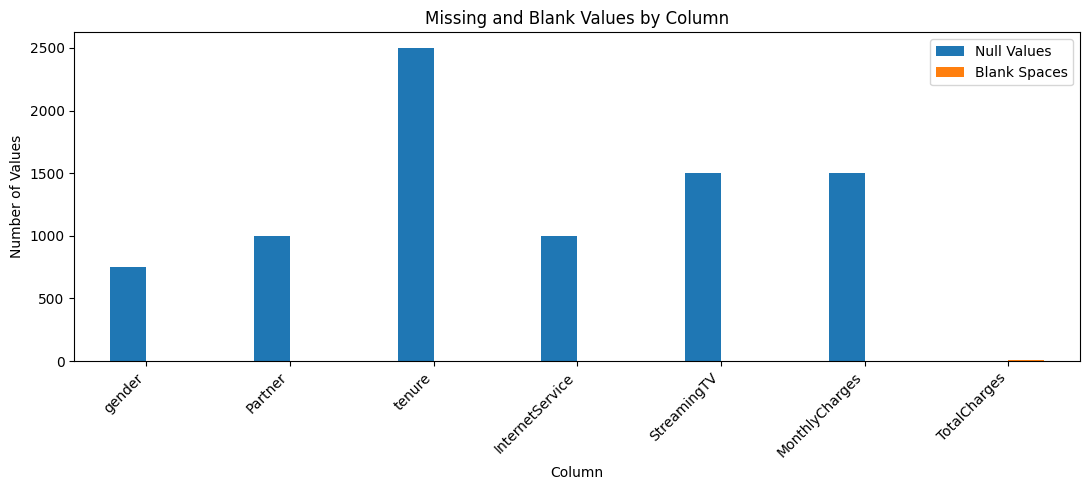

In [ ]:
#3

# Create a copy for the initial data quality check
df_check = df.copy()

# Count missing values and blank strings
null_counts = df_check.isnull().sum()

# Count blank or whitespace-only values in text columns.
blank_counts = df_check.select_dtypes(
    include=['object', 'string']
).apply(
    lambda col: col.astype('string').str.strip().eq('').sum()
)
# Create a report showing null values and blank spaces for each column.
missing_report = pd.DataFrame({
    'Null Values': null_counts,
    'Blank Spaces': blank_counts.reindex(
        df_check.columns, fill_value=0
    )
})
# Calculate the total number of missing and blank values in each column.
missing_report['Total Missing/Blank'] = (
    missing_report['Null Values'] +
    missing_report['Blank Spaces']
)

print("Initial missing-value report:")
display(
    missing_report[
        missing_report['Total Missing/Blank'] > 0
    ].sort_values('Total Missing/Blank', ascending=False)
)

# Visualize missing and blank values
missing_to_plot = missing_report[
    missing_report['Total Missing/Blank'] > 0
]
# Check whether any columns contain missing or blank values.
if not missing_to_plot.empty:
    missing_to_plot[
        ['Null Values', 'Blank Spaces']
    ].plot(kind='bar', figsize=(11, 5))

    plt.title('Missing and Blank Values by Column')
    plt.xlabel('Column')
    plt.ylabel('Number of Values')
    plt.xticks(rotation=45, ha='right') # Rotate the column labels to improve readability.
    plt.tight_layout()  # Adjust spacing
    plt.show()
else:
    print("No missing or blank values found.")


In [ ]:
#4

# Convert blank or whitespace-only strings into NaN
df = df.replace(r'^\s*$', np.nan, regex=True)

# Churn is the target and must be available for supervised learning
if 'Churn' not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' column.")

print("Rows with missing Churn:", df['Churn'].isna().sum())

# Remove rows whose target is missing
df = df.dropna(subset=['Churn']).copy()

# Normalize target labels
df['Churn'] = df['Churn'].astype(str).str.strip()

# Keep only valid target labels
df = df[df['Churn'].isin(['Yes', 'No'])].copy()

# Convert known numeric columns safely
known_numeric = [
    'tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen'
]

for col in known_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Split the data
train_raw, test_raw = train_test_split(
    df,
    test_size=0.30,
    stratify=df['Churn'],
    random_state=42
)

# Create independent working copies
df_train = train_raw.copy()
df_test = test_raw.copy()

print("Training set shape:", df_train.shape)
print("Testing set shape:", df_test.shape)

print("\nTraining Churn distribution:")
display(df_train['Churn'].value_counts().to_frame('Count'))

print("\nTesting Churn distribution:")
display(df_test['Churn'].value_counts().to_frame('Count'))


Rows with missing Churn: 0
Training set shape: (4930, 21)
Testing set shape: (2113, 21)

Training Churn distribution:


,Count
Churn,
No,3622
Yes,1308



Testing Churn distribution:


,Count
Churn,
No,1552
Yes,561


,Before Imputation,After Imputation
Training Set,5781,5781
Testing Set,2480,2480


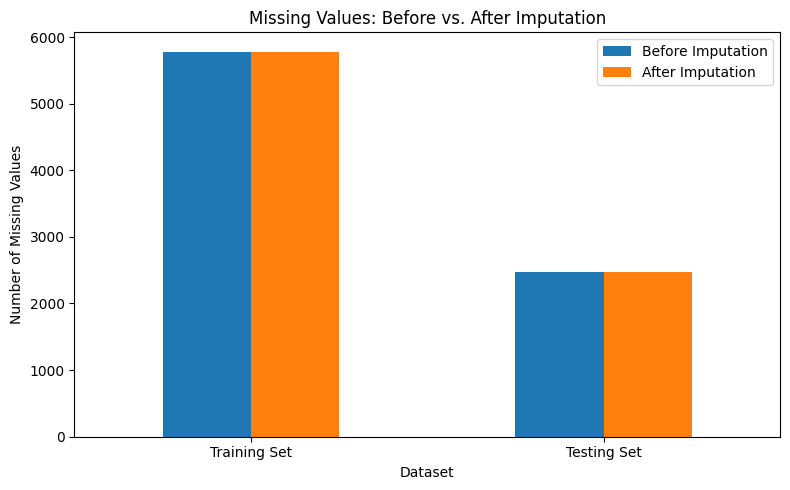

In [ ]:
#5

# Compare missing values before and after imputation
missing_comparison = pd.DataFrame({
    # Count all missing values in the original training and testing sets.
    'Before Imputation': [
        train_raw.isnull().sum().sum(),
        test_raw.isnull().sum().sum()
    ],
    'After Imputation': [
        df_train.isnull().sum().sum(),
        df_test.isnull().sum().sum()
    ]
}, index=['Training Set', 'Testing Set'])

display(missing_comparison) # Display the comparison table.

missing_comparison.plot(kind='bar', figsize=(8, 5))
plt.title('Missing Values: Before vs. After Imputation')
plt.xlabel('Dataset')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
#6

# Identify numeric and categorical columns
# Separate columns by data type so that missing values can be handled appropriately.
# Numeric columns will use the median, while categorical columns will use the most frequent value.
numeric_cols = df_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols = df_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Do not impute the target as a feature
# Churn is the target variable that indicates whether a customer leaves the service.
# It must remain separate from the input features used for data preprocessing.
numeric_cols = [c for c in numeric_cols if c != 'Churn']
categorical_cols = [c for c in categorical_cols if c != 'Churn']

# Convert numeric-looking text columns when appropriate
# Some columns may contain numbers stored as text instead of numeric data types.
# Converting them allows numerical operations, such as calculating the median, to work correctly.
for col in categorical_cols.copy():
    # Attempt to convert the column to numeric values.
    # Invalid values become NaN instead of causing the conversion to fail.
    train_numeric = pd.to_numeric(df_train[col], errors='coerce')
    non_missing = df_train[col].notna()

    # Convert if every nonblank training value can be interpreted as numeric
    # This condition avoids converting a column when its non-missing training values
    # contain actual text categories that should remain categorical.
    if non_missing.sum() > 0 and train_numeric[non_missing].notna().all():
        # Replace the training column with its numeric representation.
        df_train[col] = train_numeric

        # Apply the same numeric conversion to the corresponding testing column.
        # The testing data is converted using the decision made from the training data.
        df_test[col] = pd.to_numeric(df_test[col], errors='coerce')

        # Update the column lists so that this column is processed as numeric.
        categorical_cols.remove(col)
        numeric_cols.append(col)

# Calculate imputation values from training data only
# Imputation values are learned from the training set to prevent information leakage.
# The same values will then be applied to both training and testing data.
numeric_fill_values = {}

for col in numeric_cols:
    # Use the median because it is less affected by extreme values than the mean.
    median_value = df_train[col].median()

    # Use 0 as a fallback if the median cannot be calculated.
    # This can happen when a column contains no usable numeric values.
    numeric_fill_values[col] = (
        median_value if pd.notna(median_value) else 0
    )

# Prepare fill values for categorical columns.
categorical_fill_values = {}

for col in categorical_cols:
    # Find the most frequently occurring non-missing category in the training data.
    modes = df_train[col].mode(dropna=True)

    # Use the first mode when available.
    # If no valid category exists, use 'Unknown' as a fallback value.
    categorical_fill_values[col] = (
        modes.iloc[0] if not modes.empty else 'Unknown'
    )

# Apply numeric imputation
# Fill missing numeric values with the medians calculated from the training set.
# Using the same fill values for both sets keeps preprocessing consistent.
for col, fill_value in numeric_fill_values.items():
    df_train[col] = df_train[col].fillna(fill_value)
    df_test[col] = df_test[col].fillna(fill_value)

# Apply categorical imputation
# Fill missing categorical values with the most frequent training category.
# This preserves existing non-missing values while replacing missing entries.
for col, fill_value in categorical_fill_values.items():
    df_train[col] = df_train[col].fillna(fill_value)
    df_test[col] = df_test[col].fillna(fill_value)

# Verify missing values
# Count all remaining missing cells in each dataset.
# A result of 0 indicates that no null values remain in the respective DataFrame.
print("Missing values after imputation — training:")
print(df_train.isnull().sum().sum())

print("\nMissing values after imputation — testing:")
print(df_test.isnull().sum().sum())

# Display sample records to inspect the results of preprocessing.
# Viewing examples helps confirm that the columns and values remain readable.
print("\nProcessed training sample:")
display(df_train.head())

print("\nProcessed testing sample:")
display(df_test.head())

Missing values after imputation — training:
0

Missing values after imputation — testing:
0

Processed training sample:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5557,6918-UMQCG,Female,0,No,No,5.0,Yes,No,Fiber optic,No,...,No,No,Yes,No,Month-to-month,No,Electronic check,80.20,384.25,No
2270,4140-MUHUG,Female,1,No,No,3.0,Yes,No,Fiber optic,No,...,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,86.85,220.95,Yes
6930,5570-PTWEH,Female,0,Yes,No,3.0,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.15,216.75,Yes
2257,2054-PJOCK,Female,0,No,No,60.0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,Yes,One year,No,Credit card (automatic),80.55,4847.05,No
898,4315-MURBD,Female,0,No,No,30.0,Yes,No,Fiber optic,Yes,...,No,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),98.90,1120.95,Yes



Processed testing sample:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
4994,9692-TUSXH,Female,0,No,No,18.0,Yes,No,Fiber optic,Yes,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.05,1740.70,Yes
6828,2005-DWQZJ,Female,0,Yes,Yes,8.0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.05,201.70,No
755,6683-VLCTZ,Male,1,No,No,30.0,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,70.75,1842.80,Yes
404,5495-GPSRW,Male,0,No,No,20.0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Mailed check,19.70,419.40,No
981,1106-HRLKZ,Male,0,Yes,Yes,30.0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.60,808.95,No


Training set: (4930, 21)
Testing set: (2113, 21)
Created feature: tenure_group


,tenure,tenure_group
5557,5.0,0-12 months
2270,3.0,0-12 months
6930,3.0,0-12 months
2257,60.0,49+ months
898,30.0,25-48 months
3828,65.0,49+ months
2147,18.0,13-24 months
3149,30.0,25-48 months
5401,31.0,25-48 months
2062,66.0,49+ months



TRAINING Churn distribution:
Churn
No     0.734686
Yes    0.265314
Name: proportion, dtype: float64

TESTING Churn distribution:
Churn
No     0.734501
Yes    0.265499
Name: proportion, dtype: float64


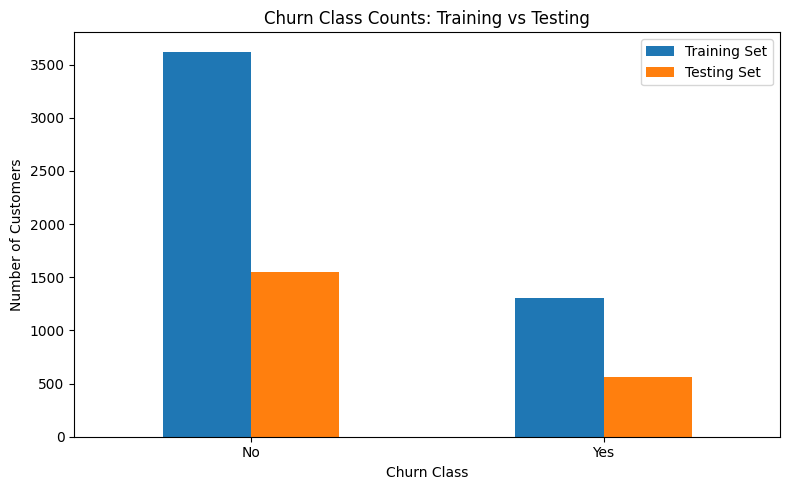

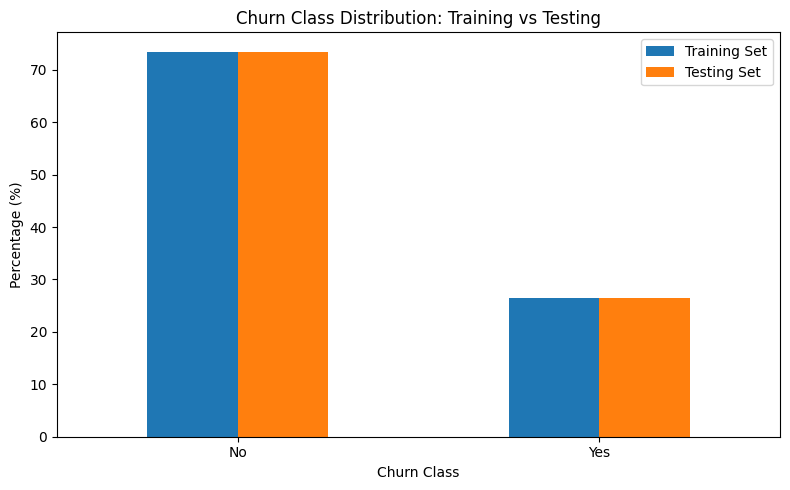

In [ ]:

#7

# Display the number of rows and columns in the original training and testing datasets.
# The shape property returns (number of rows, number of columns).
# This helps verify the dataset sizes after the train-test split.
print("Training set:", train_raw.shape)
print("Testing set:", test_raw.shape)

# Create a tenure group feature if tenure exists
# Feature engineering creates a new feature from an existing column.
# Here, customer tenure is grouped into ranges to make customer loyalty easier to analyze.
# Checking for the column first prevents errors if tenure is unavailable.
if 'tenure' in df_train.columns:
    # Define the boundaries for the tenure groups.
    # Negative and positive infinity allow the first and last groups to cover all remaining values.
    tenure_bins = [-np.inf, 12, 24, 48, np.inf]

    # Assign a readable label to each tenure range.
    # These labels describe how long a customer has stayed with the service.
    tenure_labels = [
        '0-12 months',
        '13-24 months',
        '25-48 months',
        '49+ months'
    ]

    # Apply the same feature engineering rules to both datasets.
    # Using identical boundaries keeps the new feature consistent between training and testing.
    for data in [df_train, df_test]:
        # pd.cut() assigns each tenure value to its corresponding interval.
        # include_lowest=True includes the lowest boundary in the first interval.
        # astype(str) converts the resulting categories into strings for later categorical encoding.
        data['tenure_group'] = pd.cut(
            data['tenure'],
            bins=tenure_bins,
            labels=tenure_labels,
            include_lowest=True
        ).astype(str)

    # Confirm that the new feature was created successfully.
    print("Created feature: tenure_group")

    # Display the original tenure values alongside their new group labels.
    # The first 10 rows provide a quick sample for checking the grouping results.
    display(
        df_train[['tenure', 'tenure_group']].head(10)
    )
else:
    # Report why feature engineering was not performed.
    print("Feature engineering skipped: tenure column not found.")

# Display the Churn distribution in the training data.
# normalize=True returns proportions instead of raw customer counts.
# This helps show the percentage of customers who stayed or left.
print("\nTRAINING Churn distribution:")
print(train_raw['Churn'].value_counts(normalize=True))

# Display the Churn distribution in the testing data.
# Comparing these proportions helps check whether stratified splitting
# maintained a similar target-class distribution in both sets.
# This is a split diagnostic, not a reason to make preprocessing decisions using test data.
print("\nTESTING Churn distribution:")
print(test_raw['Churn'].value_counts(normalize=True))




# ==========================================
# 1. Count Churn classes in the training set
# ==========================================

# Count how many customers have Churn = No and Churn = Yes.
# value_counts() calculates the number of records in each class.
# reindex() keeps the order as No first and Yes second.
# fill_value=0 means a missing class will be shown as 0.
train_counts = train_raw['Churn'].value_counts().reindex(
    ['No', 'Yes'], fill_value=0
)

# Count Churn classes in the testing set.
# We use the same class order to make the charts easy to compare.
test_counts = test_raw['Churn'].value_counts().reindex(
    ['No', 'Yes'], fill_value=0
)


# ==========================================
# 2. Calculate Churn percentages
# ==========================================

# normalize=True changes the counts into proportions.
# Multiply by 100 to show the results as percentages.
# This helps compare the class distribution between both sets,
# even though the training set contains more records than the testing set.
train_pct = (
    train_raw['Churn']
    .value_counts(normalize=True)
    .reindex(['No', 'Yes'], fill_value=0) * 100
)

# Calculate the percentage of each Churn class in the testing set.
# Using the same class order ensures the results align correctly in the chart.
test_pct = (
    test_raw['Churn']
    .value_counts(normalize=True)
    .reindex(['No', 'Yes'], fill_value=0) * 100
)


# ==========================================
# 3. Plot the number of customers
# ==========================================

# Put both sets into one DataFrame.
# Each row represents a Churn class.
# Each column represents a dataset.
# This structure allows pandas to plot both datasets side by side.
counts_df = pd.DataFrame({
    'Training Set': train_counts,
    'Testing Set': test_counts
})

# Create a bar chart to compare customer counts.
# The bars show how many No and Yes customers are in each set.
counts_df.plot(kind='bar', figsize=(8, 5))

# Add a title and labels to explain the chart.
# Clear labels help readers understand what each axis represents.
plt.title('Churn Class Counts: Training vs Testing')
plt.xlabel('Churn Class')
plt.ylabel('Number of Customers')

# Keep the class labels horizontal for easier reading.
plt.xticks(rotation=0)

# Show which bars belong to the training and testing sets.
plt.legend()

# Adjust the layout to prevent labels from being cut off.
plt.tight_layout()

# Display the first chart.
plt.show()


# ==========================================
# 4. Plot the Churn percentages
# ==========================================

# Put the percentages from both sets into one DataFrame.
# The percentages allow a fairer comparison of class proportions
# because the training and testing sets have different numbers of records.
pct_df = pd.DataFrame({
    'Training Set': train_pct,
    'Testing Set': test_pct
})

# Create a second bar chart to compare percentages.
# Percentages are useful because the two sets have different sizes.
ax = pct_df.plot(kind='bar', figsize=(8, 5))

# Add a title and labels to explain the percentage chart.
ax.set_title('Churn Class Distribution: Training vs Testing')
ax.set_xlabel('Churn Class')
ax.set_ylabel('Percentage (%)')

# Keep the labels in the same order: No, then Yes.
ax.set_xticklabels(['No', 'Yes'], rotation=0)

# Show the legend for both datasets.
ax.legend()

# Adjust the layout so all labels are visible.
plt.tight_layout()

# Display the second chart.
plt.show()


In [ ]:
#8

# Separate target and features
y_train = df_train['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
y_test = df_test['Churn'].map({'No': 0, 'Yes': 1}).astype(int)

X_train = df_train.drop(columns=['Churn']).copy()
X_test = df_test.drop(columns=['Churn']).copy()

# Remove the customer identifier from model features
id_columns = [
    col for col in X_train.columns
    if col.lower() in ['customerid', 'customer_id', 'customer id']
]

X_train = X_train.drop(columns=id_columns, errors='ignore')
X_test = X_test.drop(columns=id_columns, errors='ignore')

# Find categorical columns from the training set
categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'string', 'bool']
).columns.tolist()

# One-hot encode both datasets
X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_features,
    dtype=int
)

# Make sure the test features match the training features
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Confirm the features are numeric and aligned
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: 'No', 1: 'Yes'}))

print("\nTesting target distribution:")
display(y_test.value_counts().rename(index={0: 'No', 1: 'Yes'}))

print("\nNon-numeric training features:")
print(X_train.select_dtypes(exclude='number').columns.tolist())

print("\nMissing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

display(X_train.head())


Training features: (4930, 49)
Testing features: (2113, 49)

Training target distribution:


,count
Churn,
No,3622
Yes,1308



Testing target distribution:


,count
Churn,
No,1552
Yes,561



Non-numeric training features:
[]

Missing values in training features: 0
Missing values in testing features: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12 months,tenure_group_13-24 months,tenure_group_25-48 months,tenure_group_49+ months
5557,0,5.0,80.20,384.25,1,0,1,0,1,0,...,1,0,0,0,1,0,1,0,0,0
2270,1,3.0,86.85,220.95,1,0,1,0,1,0,...,0,1,0,0,1,0,1,0,0,0
6930,0,3.0,75.15,216.75,1,0,0,1,1,0,...,0,1,0,1,0,0,1,0,0,0
2257,0,60.0,80.55,4847.05,1,0,1,0,1,0,...,1,0,0,1,0,0,0,0,0,1
898,0,30.0,98.90,1120.95,1,0,1,0,1,0,...,0,1,1,0,0,0,0,0,1,0


In [ ]:
#9

# Select continuous numerical columns that actually exist
candidate_scaler_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

columns_scaler = [
    col for col in candidate_scaler_cols
    if col in X_train.columns and col in X_test.columns
]

if not columns_scaler:
    raise ValueError(
        "No continuous numeric columns were found for Standard Scaling. "
        "Check the dataset column names and preprocessing steps."
    )

print("Columns selected for scaling:", columns_scaler)

# Save the original values for comparison
X_train_before = X_train[columns_scaler].copy()

# Fit the scaler using training data only
scaler = StandardScaler()

X_train.loc[:, columns_scaler] = scaler.fit_transform(
    X_train[columns_scaler]
)

# Apply the training scaler to test data
X_test.loc[:, columns_scaler] = scaler.transform(
    X_test[columns_scaler]
)

print("\nMeans after scaling (training):")
display(X_train[columns_scaler].mean().round(3))

print("\nPopulation standard deviations after scaling (training):")
display(X_train[columns_scaler].std(ddof=0).round(3))

print("\nFirst 5 rows after scaling:")
display(X_train[columns_scaler].head())


Columns selected for scaling: ['tenure', 'MonthlyCharges', 'TotalCharges']

Means after scaling (training):


,0
tenure,0.0
MonthlyCharges,-0.0
TotalCharges,0.0



Population standard deviations after scaling (training):


,0
tenure,1.0
MonthlyCharges,1.0
TotalCharges,1.0



First 5 rows after scaling:


,tenure,MonthlyCharges,TotalCharges
5557,-1.359609,0.518592,-0.837871
2270,-1.461192,0.765368,-0.909151
6930,-1.461192,0.331191,-0.910985
2257,1.433911,0.531580,1.110142
898,-0.089827,1.212533,-0.516301


BEFORE SCALING:


,tenure,MonthlyCharges,TotalCharges
5557,5.0,80.20,384.25
2270,3.0,86.85,220.95
6930,3.0,75.15,216.75
2257,60.0,80.55,4847.05
898,30.0,98.90,1120.95
3828,65.0,19.35,1319.95
2147,18.0,19.00,348.80
3149,30.0,70.75,504.05
5401,31.0,20.45,638.55
2062,66.0,25.15,1683.60


AFTER SCALING:


,tenure,MonthlyCharges,TotalCharges
5557,-1.359609,0.518592,-0.837871
2270,-1.461192,0.765368,-0.909151
6930,-1.461192,0.331191,-0.910985
2257,1.433911,0.531580,1.110142
898,-0.089827,1.212533,-0.516301
3828,1.687867,-1.739501,-0.429438
2147,-0.699323,-1.752489,-0.853345
3149,-0.089827,0.167910,-0.785578
5401,-0.039036,-1.698681,-0.726869
2062,1.738659,-1.524268,-0.270704


Statistics Comparison:


,Mean Before,Mean After,Std Before,Std After
tenure,31.769,0.0,19.688,1.0
MonthlyCharges,66.225,-0.0,26.948,1.0
TotalCharges,2303.770,0.0,2290.950,1.0


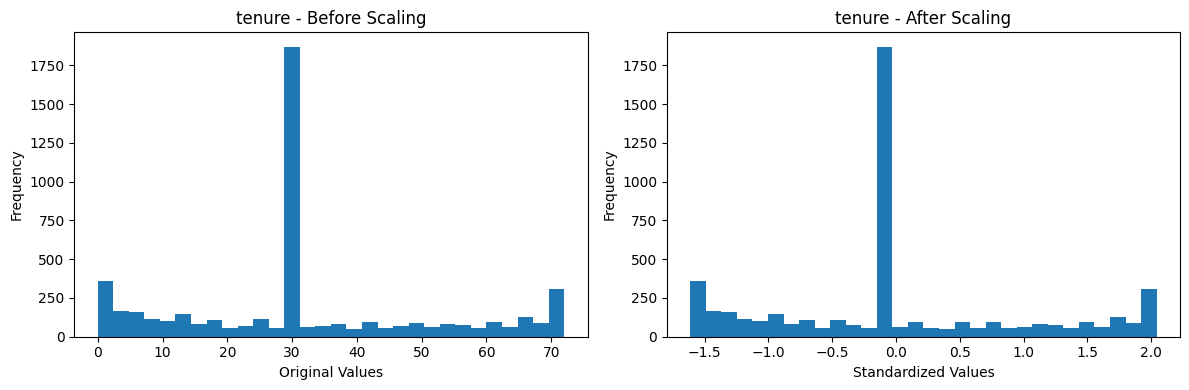

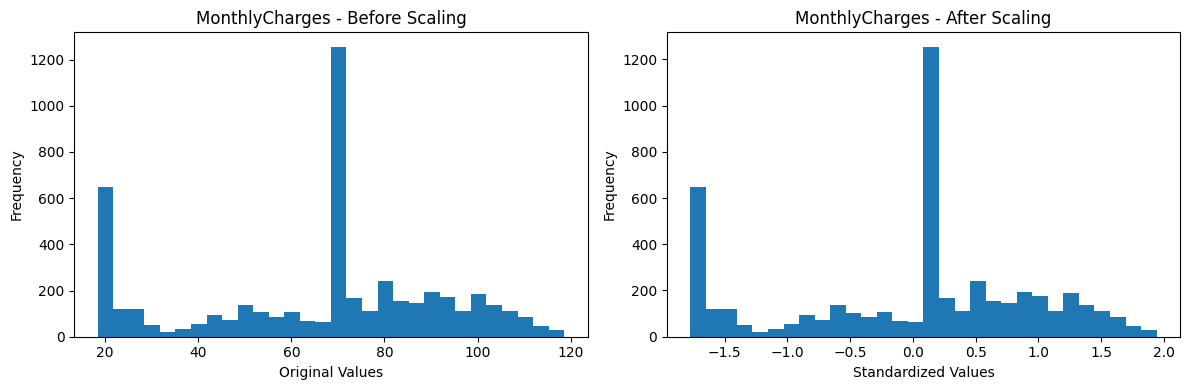

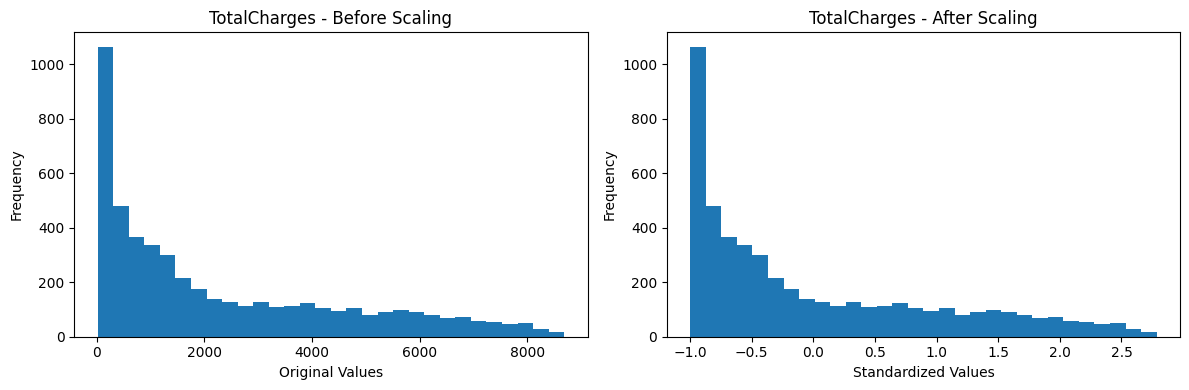

In [ ]:
#10

# Compare the first 10 rows
print("BEFORE SCALING:")
display(X_train_before.head(10))

print("AFTER SCALING:")
display(X_train[columns_scaler].head(10))

# Compare the same columns before and after scaling
comparison = pd.DataFrame({
    'Mean Before': X_train_before.mean(),
    'Mean After': X_train[columns_scaler].mean(),
    'Std Before': X_train_before.std(ddof=0),
    'Std After': X_train[columns_scaler].std(ddof=0)
})

print("Statistics Comparison:")
display(comparison.round(3))

# Plot the distributions
for column in columns_scaler:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(X_train_before[column].dropna(), bins=30)
    axes[0].set_title(f'{column} - Before Scaling')
    axes[0].set_xlabel('Original Values')
    axes[0].set_ylabel('Frequency')

    axes[1].hist(X_train[column].dropna(), bins=30)
    axes[1].set_title(f'{column} - After Scaling')
    axes[1].set_xlabel('Standardized Values')
    axes[1].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()


Training class counts BEFORE balancing:


,Count
No,3622
Yes,1308


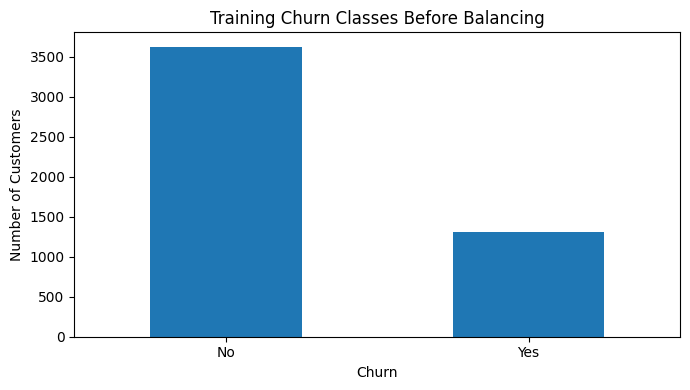

Training class counts AFTER balancing:


,Count
No,3622
Yes,3622


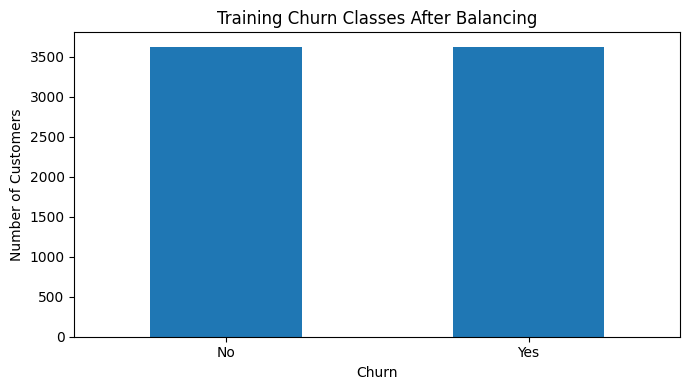


Original training feature shape: (4930, 49)
Balanced training feature shape: (7244, 49)
Test feature shape (unchanged): (2113, 49)


In [ ]:
#11

# Plot the class distribution before balancing
before_counts = y_train.value_counts().reindex([0, 1], fill_value=0)
before_counts.index = ['No', 'Yes']

print("Training class counts BEFORE balancing:")
display(before_counts.to_frame('Count'))

before_counts.plot(kind='bar', figsize=(7, 4))
plt.title('Training Churn Classes Before Balancing')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Apply Random Oversampling to training data only
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train, y_train
)

# Plot the class distribution after balancing
after_counts = y_train_balanced.value_counts().reindex(
    [0, 1], fill_value=0
)
after_counts.index = ['No', 'Yes']

print("Training class counts AFTER balancing:")
display(after_counts.to_frame('Count'))

after_counts.plot(kind='bar', figsize=(7, 4))
plt.title('Training Churn Classes After Balancing')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nOriginal training feature shape:", X_train.shape)
print("Balanced training feature shape:", X_train_balanced.shape)
print("Test feature shape (unchanged):", X_test.shape)


In [ ]:

#12

# Compare raw and processed dataset sizes
# Create a summary table to compare the original and processed training/testing datasets.
# This report helps check the effects of preprocessing on dataset size and missing values.
# The original datasets provide a baseline for evaluating the preprocessing results.
final_report = pd.DataFrame({
    'Original Training': [
        # Count the original training records.
        len(train_raw),

        # Count all missing cells in the original training dataset.
        train_raw.isnull().sum().sum()
    ],
    'Processed Training': [
        # Count the training feature records after preprocessing.
        len(X_train),

        # Count any remaining missing cells in the processed training features.
        X_train.isnull().sum().sum()
    ],
    'Original Testing': [
        # Count the original testing records.
        len(test_raw),

        # Count all missing cells in the original testing dataset.
        test_raw.isnull().sum().sum()
    ],
    'Processed Testing': [
        # Count the testing feature records after preprocessing.
        len(X_test),

        # Count any remaining missing cells in the processed testing features.
        X_test.isnull().sum().sum()
    ]
}, index=['Number of Rows', 'Missing Values'])

# Display the comparison report.
# A missing-value count of 0 in the processed features indicates that
# missing-value handling was successful for those feature datasets.
print("Original vs Processed Data Report:")
display(final_report)

# Compare Churn percentages before and after balancing
# Calculate the percentage of each target class in the original training labels,
# the balanced training labels, and the untouched testing labels.
# This comparison shows how Random Oversampling changes the training distribution
# while allowing the testing distribution to remain representative of the original split.
churn_summary = pd.DataFrame({
    # Calculate the percentage of each class in the training set before balancing.
    # normalize=True converts counts into proportions, and multiplying by 100 gives percentages.
    'Original Training (%)': y_train.value_counts(
        normalize=True
    ).reindex([0, 1], fill_value=0) * 100,

    # Calculate the percentage of each class after Random Oversampling.
    # If balancing succeeds, the two classes should each represent approximately 50%.
    'Balanced Training (%)': y_train_balanced.value_counts(
        normalize=True
    ).reindex([0, 1], fill_value=0) * 100,

    # Calculate the class percentages in the testing set.
    # The test labels are not oversampled so they can be used for evaluation
    # without the artificial class balance introduced into the training data.
    'Testing (%)': y_test.value_counts(
        normalize=True
    ).reindex([0, 1], fill_value=0) * 100
})

# Replace numeric labels with readable class names.
# This makes the summary easier to interpret without remembering the numeric mapping.
churn_summary.index = ['No Churn', 'Churn']

# Display the class distribution comparison rounded to two decimal places.
# This allows the original, balanced, and testing distributions to be compared clearly.
print("\nChurn Distribution Comparison:")
display(churn_summary.round(2))

# Display final processed samples
# Show examples of the balanced training features after encoding and scaling.
# These rows are the input features that can be supplied to a machine learning model.
print("\nFinal processed training features:")
display(X_train_balanced.head(10))

# Display the target labels corresponding to the balanced training features.
# These labels indicate whether each training observation belongs to the No Churn or Churn class.
print("\nFinal training target:")
display(y_train_balanced.head(10))

# Show examples of the processed testing features.
# These features use the same column structure as the training features
# but remain unbalanced for a more realistic evaluation.
print("\nFinal processed testing features:")
display(X_test.head(10))

# Display the target labels corresponding to the testing features.
# The model's predictions can later be compared with these actual labels.
print("\nFinal testing target:")
display(y_test.head(10))

# Final validation
# Check that training and testing have the same number of feature columns.
# This is necessary because the model expects consistent input features.
assert X_train_balanced.shape[1] == X_test.shape[1]

# Verify that the balanced training features contain no missing values.
assert X_train_balanced.isnull().sum().sum() == 0

# Verify that the testing features contain no missing values.
assert X_test.isnull().sum().sum() == 0

# Confirm that every balanced training feature row has a corresponding target label.
assert len(X_train_balanced) == len(y_train_balanced)

# Confirm that every testing feature row has a corresponding target label.
assert len(X_test) == len(y_test)

# If any assertion fails, Python raises an AssertionError and stops execution.
# If all checks pass, the following messages confirm that the final checks succeeded.
print("\nAll final validation checks passed.")

# Identify the feature and target datasets to use when training the model.
print("Use X_train_balanced and y_train_balanced for model training.")

# Identify the untouched testing features and labels to use for final evaluation.
print("Use X_test and y_test for model evaluation.")


Original vs Processed Data Report:


,Original Training,Processed Training,Original Testing,Processed Testing
Number of Rows,4930,4930,2113,2113
Missing Values,5781,0,2480,0



Churn Distribution Comparison:


,Original Training (%),Balanced Training (%),Testing (%)
No Churn,73.47,50.0,73.45
Churn,26.53,50.0,26.55



Final processed training features:


...


Final processed testing features:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12 months,tenure_group_13-24 months,tenure_group_25-48 months,tenure_group_49+ months
4994,0,-0.699323,1.106772,-0.245780,1,0,1,0,1,0,...,0,1,0,0,1,0,0,1,0,0
6828,0,-1.207236,-1.750633,-0.917554,1,0,0,1,0,1,...,1,0,0,0,0,1,1,0,0,0
755,1,-0.089827,0.167910,-0.201214,0,1,1,0,1,0,...,0,1,0,0,1,0,0,0,1,0
404,0,-0.597740,-1.726512,-0.822528,0,1,1,0,1,0,...,0,1,0,0,0,1,0,1,0,0
981,0,-0.089827,-1.730223,-0.652489,0,1,0,1,0,1,...,1,0,0,0,0,1,0,0,1,0
4686,1,-0.089827,1.527961,2.376735,1,0,1,0,1,0,...,0,1,1,0,0,0,0,0,1,0
2791,0,1.281537,0.301503,0.878928,0,1,1,0,1,0,...,0,1,1,0,0,0,0,0,0,1
6155,0,-0.089827,-1.739501,-0.950575,0,1,0,1,1,0,...,1,0,0,0,0,1,0,0,1,0
1244,0,-0.089827,0.167910,-0.879317,0,1,1,0,1,0,...,1,0,1,0,0,0,0,0,1,0
4301,0,-0.089827,-1.724657,-0.418722,0,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0



Final testing target:


,Churn
4994,1
6828,0
755,1
404,0
981,0
4686,0
2791,0
6155,1
1244,1
4301,0



All final validation checks passed.
Use X_train_balanced and y_train_balanced for model training.
Use X_test and y_test for model evaluation.


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1. Create a fresh copy and clean column names
df_processed = df_train.copy()
df_processed.columns = df_processed.columns.str.strip()

# 2. Drop customerID
if 'customerID' in df_processed.columns:
    df_processed = df_processed.drop(columns=['customerID'])
    print("✓ Removed 'customerID'")

# 3. Clean and scale numeric columns (tenure, MonthlyCharges, TotalCharges)
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
for col in numeric_cols:
    if col in df_processed.columns:
        df_processed[col] = pd.to_numeric(df_processed[col], errors='coerce')
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())

scaler = MinMaxScaler()
existing_numeric = [c for c in numeric_cols if c in df_processed.columns]
if existing_numeric:
    df_processed[existing_numeric] = scaler.fit_transform(df_processed[existing_numeric])
    print(f"✓ Scaled numeric columns between 0 and 1: {existing_numeric}")

# 4. Convert all text/category columns to numbers (0s and 1s)
categorical_cols = df_processed.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    unique_vals = df_processed[col].dropna().unique()
    if len(unique_vals) == 2:
        df_processed[col] = df_processed[col].map({unique_vals[0]: 0, unique_vals[1]: 1})
    else:
        dummies = pd.get_dummies(df_processed[col], prefix=col, drop_first=True, dtype=int)
        df_processed = pd.concat([df_processed.drop(columns=[col]), dummies], axis=1)

print(f"✓ All text columns converted. Final dataset has {df_processed.shape[1]} numeric columns.")

# 5. Save and download
output_filename = 'telco_fully_processed_all_columns.csv'
df_processed.to_csv(output_filename, index=False)

from google.colab import files
files.download(output_filename)

✓ Removed 'customerID'
✓ Scaled numeric columns between 0 and 1: ['tenure', 'MonthlyCharges', 'TotalCharges']
✓ All text columns converted. Final dataset has 34 numeric columns.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>